In [1]:
import math
from math import sqrt

In [2]:
import requests
# We need coordinates to get weather data
latitude = 48.85   # Paris latitude
longitude = 2.35   # Paris longitude
# Build the API URL with our parameters
url = f"https://api.open-meteo.com/v1/forecast?latitude={latitude}&longitude={longitude}&current=temperature_2m"
# Make the request
response = requests.get(url)
data = response.json()
print(data)

{'latitude': 48.84, 'longitude': 2.3599997, 'generationtime_ms': 0.02682209014892578, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 46.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C'}, 'current': {'time': '2026-10-01T07:15', 'interval': 900, 'temperature_2m': 16.8}}


In [3]:
import requests
from datetime import datetime, timedelta
# Calculate dates
today = datetime.now()
week_ago = today - timedelta(days=7)
# Format dates for API (YYYY-MM-DD)
start_date = week_ago.strftime("%Y-%m-%d")
end_date = today.strftime("%Y-%m-%d")
# Get Paris weather for past week
url = f"https://api.open-meteo.com/v1/forecast?latitude=48.85&longitude=2.35&start_date={start_date}&end_date={end_date}&daily=temperature_2m_max,temperature_2m_min"
response = requests.get(url)
data = response.json()
print(data)

{'latitude': 48.84, 'longitude': 2.3599997, 'generationtime_ms': 0.7035732269287109, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 46.0, 'daily_units': {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C'}, 'daily': {'time': ['2026-09-24', '2026-09-25', '2026-09-26', '2026-09-27', '2026-09-28', '2026-09-29', '2026-09-30', '2026-10-01'], 'temperature_2m_max': [23.2, 27.8, 22.1, 27.9, 24.1, 28.2, 22.8, 20.6], 'temperature_2m_min': [15.1, 13.9, 15.5, 13.7, 17.7, 17.0, 19.7, 15.6]}}


In [5]:
import pandas as pd
daily_data = data['daily']
df = pd.DataFrame({
    'date': daily_data['time'],
    'max_temp': daily_data['temperature_2m_max'],
    'min_temp': daily_data['temperature_2m_min']
})
df["date"] = pd.to_datetime(df["date"])
print(df)

        date  max_temp  min_temp
0 2026-09-24      23.2      15.1
1 2026-09-25      27.8      13.9
2 2026-09-26      22.1      15.5
3 2026-09-27      27.9      13.7
4 2026-09-28      24.1      17.7
5 2026-09-29      28.2      17.0
6 2026-09-30      22.8      19.7
7 2026-10-01      20.6      15.6


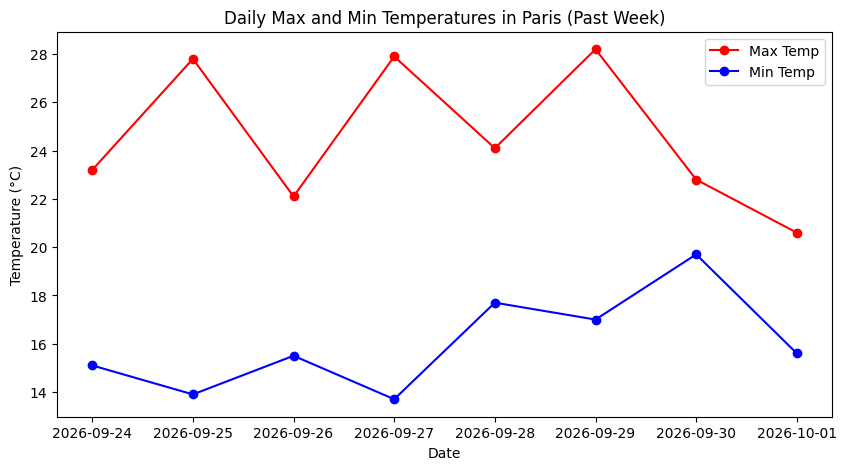

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(df['date'], df['max_temp'], label='Max Temp', color='red', marker='o')    
plt.plot(df['date'], df['min_temp'], label='Min Temp', color='blue', marker='o')
plt.title('Daily Max and Min Temperatures in Paris (Past Week)')

plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()

# Save the plot
plt.savefig('weather_chart.png')
plt.show()